# Disturbance Event Generator (v0.1b)

This notebook contains a prototype of the _disturbance event generator_ (DEG) module (version 0.1beta). The purpose of this module is to generate disturbance event data (in GeoTIFF format) which will be used as input to the GCBM carbon modelling software framework.

### Note from the developer (Greg Paradis) to potential users of this software prototype
This is a fully functional *beta prototype* of the DEG module. A beta prototype implements all the features of a production-grade system, and has undergone extensive testing, but is still under active development. There may be bugs. These will need to be fixed as they are found. 

The DEG is implemented in a JupyterLab notebook interface. The notebook interface is very powerful and flexible, but it is very "raw". Think of this as a small airplane: can get you to all sorts of places and relatively easy to operate under best-case scenarios, but acquiring the knowledge required to diagnose and correctly respond to every possible worst-case scenario (i.e., getting your "pilot licence") may be a lengthy process. You are responsible for self-assessing your compentency level, and self-prescribe the required training prior to using the DEG (in a production setting).

Remember that the DEG sits at the beginning of a sequential daisy-chain of software module (DEG>CBM>HWP>MEA). If you were to skip ahead and run the DEG before acquiring all the knowledge required to responsibly perform this task (i.e., systematically detect and deal with *badness*, in all its forms, when it manifests), then you may generate trillions of garbage pixels, waste a lot of time feeding them through downstream models, compiling garbage results, etc. The three downstream modules (i.e., CBM>HWP>MEA) run about 1000 times slower than then DEG module, so hastily pushing ahead with bad DEG output can mean backtracking all the way to the beginning of a very expensive process.  Also, the larger the scale of the datasets, the harder it is to detect badness. Make sure you test the full workflow on incrementally larger datasets, before proceeding with final processing of very-large datasets. Again, there is no magic trick that makes skipping this part acceptable. 

In a nutshell: doing even a minimally-acceptable professional job of simulating all future anthropic and natural disturbance events, looking forward 100 yearly time steps, on 100 million pixels worth of forest, for multiple scenarios (while maintaining coherence between scenarios, such that they are conceptually suitable for cross-scenario comparison later on), is a very (very) big and difficult task. **As far as I am concerned, the task of running the DEG (in a production setting) should be exclusively performed by (or under the direct supervision of) an experienced wood supply analyst (who is a registered professional forester [RPF], and has undergone all the training required to be fully competent to operate the DEG).** I do not see any way to skip this requirement and still guarantee that the work is done correctly.  

### Basic DEG operating instructions

Warnings aside, the DEG is relatively simple to operate: 
1. Set the parameters correctly to model whatever it is you want to model for the a given scenario.
2. Click *Run > Run all cells*.

Easy peasy.

Step 1 is the doozie, however, and wishful thinking is going to create an expensive mess than will need to be mopped up later by the experienced wood supply analyst that should have been sitting in the pilot seat in the first place. **Do not fake step 1.** 

The DEG parameters can split into two piles: DEG-specific parameters, and ws3 parameters. 

DEG-specific parameters include local paths for input and output data, and a bunch of other stuff.   

The DEG is built on top of *ws3* (Wood Supply Simulation System), a powerful open-source software library that be used to formulate and solve large-scale wood supply problems. One can use ws3 to model all sorts of things, and this DEG prototype just one highly-specialized use-case for ws3. If you are already an expert wood supply analyst, and have several years experience building and running wood supply models (e.g., using Woodstock, Patchworks, etc.), then you already know most of what you need to know to run ws3.

In a nutshell: ws3 is a stratum-based multi-period aspatial wood supply model, which can formulate and solve Model I optimization problems, and simulate alternatiing growth and disturbance for as many iteration as you like. Anyone who has build Woodstock models will recognize most of the structure (ws3 can import andf run Woodstock models natively, or be used to automatically compile and run new models from raw input data [which is what we do in the DEG]). 

Technical documentation for ws3 can be found online at [ws3.readthedocs.io](ws3.readthedocs.io). The docs are automatically re-compiled every time the ws3 code on GitHub is updated. We are moving very fast to release this beta DEG prototype, so ws3 docs may be slightly out-of-date. If in doubt, query the inline docs for ws3 directly in the notebook, or go look at the source code. 

### More detailed DEG operating instructions

Foo.

## Preamble

Import modules, set parameters, define notebook-local functions, and such.

In [1]:
gep_dev = True
scenario_name = 'base_maxhv'

In [2]:
%matplotlib inline
%reload_ext autoreload
%load_ext line_profiler
%run -i deg
%run -i deg_params
%aimport ws3
%aimport deg
%autoreload 2
import copy

Compiled interpolation routine not available
Compiled sparse grid routine not available


In [3]:
proc_mode = 'seq_tsa'
#deg_mode = 'classic'
horizon = 1
#tsa 18, 19, 20, 26  infeasible - Saturday, April 7th, 2018

## Compile the model

In [4]:
def do_the_thing(basenames, clean_inv=False, rasterize_inv=True, run_sda=True, fm_horizon=2, pcut=1.0, pbrn=1.0):
        if clean_inv: clean_inventory()
        if rasterize_inv: rasterize_inventory(basenames, shp_path, tif_path, hdt_path, theme_cols, age_col, period_length, cap_age=80)
        hdt = {bn:pickle.load(open('%s/hdt_%s.pkl' % (hdt_path, bn), 'rb')) for bn in basenames}
        basecodes = compile_basecodes(hdt, basenames, theme_cols)
        compile_ogi = True if scenario_name in ['rogh'] else False
        fm = bootstrap_forestmodel(basenames,
                                   model_name='foo',
                                   model_path=dat_path,
                                   yld_path=yld_path,
                                   tif_path=tif_path,
                                   horizon=horizon,
                                   period_length=period_length,
                                   max_age=max_age,
                                   basecodes=basecodes,
                                   action_params=action_params,
                                   hdt=hdt,
                                   add_null_action=True,
                                   tvy_name=tvy_name,
                                   compile_actions=True,
                                   compile_ogi=compile_ogi,
                                   verbose=1)
        #deg_mode = 'classic'
        sch = run_deg(fm, basenames, scenario_name, util, tif_path, hdt, horizon, deg_mode=deg_mode, obj_mode=obj_mode, 
                      fm_horizon=fm_horizon, pcut=pcut, pbrn=pbrn)
        if run_sda:
            sda(fm, basenames, base_year, period_length, horizon, tif_path, hdt, sda_mode=sda_mode)
        deg_diagnostic1(fm, basenames, sch, util)
        if run_sda:
            deg_diagnostic2(fm, basenames, sch, figsize=(10, 10))
        return fm, sch
        #for distname in ['harvest', 'fire']:
        #    deg_diagnostic3(fm, basenames, distname)
        #zip_output(basenames, scenario_name)     - comment out April 9, 2018

In [5]:
def deg_diagnostic1(fm, basenames, sch, util=0.85, figsize=(10, 4)):
    import matplotlib.pyplot as plt
    from pandas import DataFrame as DF
    exprs = {'harvest':'totvol * %0.2f' % util, 'fire':'1.'}
    _acodes = 'harvest', 'fire'
    for bn in basenames:
        fig, ax = plt.subplots(figsize=figsize)
        mask = (bn, '?', '?', '?')
        dtype_keys = fm.unmask(mask)
        _area = {_acode:{t:0.  for t in fm.periods} for _acode in _acodes}
        for dtk, age, area, acode, period, etype in sch:
            if dtk in dtype_keys and acode in _acodes:
                _area[acode][period] += area
        d = {'t':[], 'harvest':[], 'fire':[], 
             'acut_ws3':[], 
             'acut_sch':list(_area['harvest'].values())}
        for t in fm.periods:
            d['t'].append(t)
            d['acut_ws3'].append(fm.compile_product(t, '1.', 'harvest', dtype_keys=dtype_keys))
            for acode in _acodes:
                expr = exprs[acode]
                d[acode].append(fm.compile_product(t, expr, acode, dtype_keys=dtype_keys))
        #print(d)
        df = DF(data=d).set_index('t')
        df = df.astype(int)
        df['harvest'].plot.bar(ax=ax)
        #df[['acut_ws3', 'acut_sch']].plot.bar(ax=ax)
        print(df)
        
def deg_diagnostic2(fm, basenames, sch, figsize=(10, 10), D=('harvest', 'fire'), period_length=10):
    import matplotlib.pyplot as plt
    from pandas import DataFrame as DF
    fig, ax = plt.subplots(3, 1, figsize=figsize)
    for bn in basenames:
        _sch = [x for x in sch if x[0][0] == bn]
        df = pd.DataFrame(_sch, columns=['themevals', 'age', 'area', 'action', 'period', 'foo'])
        #df = df.query('period <= 6')
        df['period'] = df['period']*period_length - period_length + 1
        df['area'] /= float(period_length)
        sch_area = df.groupby(by=['action', 'period'])['area'].sum()
        sha_area = {d:[0] for d in D}
        for i, d in enumerate(D):
            for j in range(horizon*period_length):
                path = '%s/projected_%s_%i.tif' % (tif_path(bn)[:-4], d, 2015+j)
                with rasterio.open(path) as src:
                    sha_area[d].append(src.read().sum())
        for i, d in enumerate(D):
            sch_area.loc[d].plot(style='o', ax=ax[i], label='Targeted (%s, %s)' % (bn, d))
            ax[i].plot(sha_area[d], '*', label='Scheduled (%s, %s)' % (bn, d))
            ax[i].legend()
            ax[i].set_title('Validation of targeted and scheduled area')
            plt.xlabel('Period (years)')
            plt.ylabel('Area (hectares)')
    for d in D:
        T = [x for x in sch_area.loc[d] for i in range(fm.period_length)]
        S = sha_area[d][1:]
        E = [1.-(s/t) for t, s in zip(T, S)]
        plt.plot(E, 'o', label=d)
    ax[2].set_title('Relative target shortfall')
    ax[2].set_xlabel('Period (years)')
    ax[2].set_ylabel('Proportion of target not scheduled')
    ax[2].legend()
    
    
def deg_diagnostic3(fm, basenames, distname, figsize=(15, 6)):
    import matplotlib.pyplot as plt
    from pandas import DataFrame as DF
    n = 4
    fig, ax = plt.subplots(1, 4, figsize=figsize, sharex=True, sharey=True)
    for ni, bn in enumerate(basenames):
        for j in [0, 1]:
            ax[j].set_yticklabels([])
            ax[j].set_xticklabels([])
            ax[j].set_title('%s %s (%i)' % (bn, distname, 2015+j))
            path = '%s/%s/projected_%s_%i.tif' % (os.path.split(tif_path(bn))[0], bn, distname, 2015+j)
            rasterio.plot.show(rasterio.open(path), ax=ax[j])
        for j in [2, 3]:
            ax[j].set_yticklabels([])
            ax[j].set_xticklabels([])
            year = 2015+horizon-3+(j-1)
            ax[j].set_title('%s %s (%i)' % (bn, distname, year))
            path = '%s/%s/projected_%s_%i.tif' % (os.path.split(tif_path(bn))[0], bn, distname, year)
            rasterio.plot.show(rasterio.open(path), ax=ax[j])
    plt.tight_layout()
    

In [6]:
scenario_name = 'base'
basenames = ['tsa40']
rasterize_inv = False
run_sda = False
fm_horizon = horizon
pcut = 1.0
pbrn = 1.0

Running DEG in sequential mode.
 Processing TSA tsa40
instantiating ForestModel object
bootstrap_themes
bootstrap_areas
<function <lambda> at 0x7f8ddb721e18>
bootstrap_yields
bootstrap_actions
adding null actions
compiling actions
finalizing ForestModel config
Running iteration 0
Optimize a model with 1825 rows, 2481 columns and 5053 nonzeros
Coefficient statistics:
  Matrix range     [1e-01, 9e+06]
  Objective range  [1e+00, 4e+04]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+07]
Presolve removed 1824 rows and 1925 columns
Presolve time: 0.04s
Presolved: 1 rows, 557 columns, 557 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    0.0000000e+00   4.393937e+02   0.000000e+00      0s
       1    3.9431359e+04   0.000000e+00   0.000000e+00      0s

Solved in 1 iterations and 0.11 seconds
Optimal objective  3.943135879e+04
foo
    harvest   fire  acut_ws3  acut_sch
t                                     
1  14289047  35352     39132     3

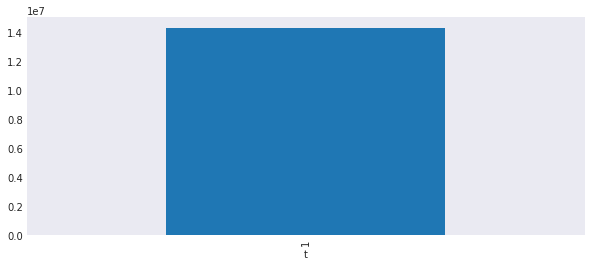

In [8]:
if proc_mode == 'seq_tsa':
    print('Running DEG in sequential mode.')
    _basenames = copy.copy(basenames)
    fm, sch = {}, {}
    for _bn in _basenames:
        print(' Processing TSA %s' % _bn)
        basenames = [_bn]
        fm[_bn], sch[_bn] = do_the_thing(basenames, 
                                         rasterize_inv=rasterize_inv,
                                         run_sda=run_sda,
                                         fm_horizon=fm_horizon, 
                                         pcut=pcut, pbrn=pbrn)
elif proc_mode == 'all_tsa':
    print('Running DEG in monolithic mode.')
    fm, sch = do_the_thing(basenames)
else:
    raise ValueError('Bad proc_mode: %s' % proc_mode)

In [ ]:
fm['tsa40'].inventory(1)

In [ ]:
fm['tsa40'].inventory(1, mask='')

In [30]:
df = pd.read_csv('../dat/targets_old20180706.csv')

In [34]:
df.query('vcut == %i' % df.vcut.max())

,tsa,period,vcut,abrn,cflw_acut_e,cgen_vcut_e,cgen_abrn_e
88,tsa24,1,128144114,56169,0.2,0.01,0.01
